### CAP 5619: AI in FinTech
+ Fall 2026
+ Hubert Antoniewicz, hu827797
+ Submission Date: November 2026
+ Homework: Bitcoin Price Prediction with Explainable AI

Predicts Bitcoin's daily price for December 2017 (one-day-ahead) from occurrence (OCC) and amount (AMO) chainlet features plus lagged prices, then explains the model with SHAP.

# Bitcoin Price Prediction with Chainlets and SHAP

### Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Dropout
from keras.models import Sequential
from keras.callbacks import EarlyStopping
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
import shap
import warnings

SEED = 100
np.random.seed(SEED)
tf.random.set_seed(SEED)
pd.set_option('display.precision', 4)

warnings.filterwarnings('ignore', category=UserWarning)
tf.get_logger().setLevel('ERROR')

DATA_DIR = 'data'

## 1. Load Data and Parse Dates

Price, occurrence (OCC) and amount (AMO) chainlet files are loaded as-is. Dates are built with datetime functions only:
+ price file: `date` parsed with an explicit format (`%m/%d/%Y %H:%M`), so month/day order can never be guessed wrong;
+ chainlet files: `year` + 1-based day-of-year converted to a date with datetime arithmetic (Jan 1 + (day - 1) days).

In [2]:
price = pd.read_csv(f'{DATA_DIR}/pricedBitcoin2009-2018.csv')
occ = pd.read_csv(f'{DATA_DIR}/OccChainletsInTime.txt', sep='\t')
amo = pd.read_csv(f'{DATA_DIR}/AmoChainletsInTime.txt', sep='\t')
price.shape, occ.shape, amo.shape

((2404, 5), (3281, 403), (3281, 403))

In [3]:
def day_of_year_to_date(year, day):
    """Convert (year, 1-based day-of-year) columns to datetimes."""
    jan1 = pd.to_datetime(pd.DataFrame({'year': year, 'month': 1, 'day': 1}))
    return jan1 + pd.to_timedelta(day - 1, unit='D')

price['date'] = pd.to_datetime(price['date'], format='%m/%d/%Y %H:%M')
# concat (not column assignment) avoids fragmenting the 403-column frames.
occ = pd.concat([day_of_year_to_date(occ['year'], occ['day']).rename('date'), occ], axis=1)
amo = pd.concat([day_of_year_to_date(amo['year'], amo['day']).rename('date'), amo], axis=1)

price.head()

,date,price,year,day,totaltx
0,2011-06-01,9.57,2011,152,6464
1,2011-06-02,10.60,2011,153,7632
2,2011-06-03,14.29,2011,154,8502
3,2011-06-04,18.89,2011,155,8766
4,2011-06-05,16.70,2011,156,8675


In [4]:
occ.iloc[:3, :6]

,date,year,day,totaltx,1:1,1:2
0,2009-01-03,2009,3,1,1,0
1,2009-01-08,2009,8,14,14,0
2,2009-01-09,2009,9,7,7,0


### Sanity Checks

Each check fails loudly if the data is not what the rest of the notebook assumes.

In [5]:
# Both date sources must agree, otherwise the merge would misalign days.
assert (price['date'].dt.year == price['year']).all()
assert (price['date'].dt.dayofyear == price['day']).all()

for name, d in [('price', price), ('occ', occ), ('amo', amo)]:
    assert d.isna().sum().sum() == 0, f'{name}: missing values'
    assert d['date'].is_unique and d['date'].is_monotonic_increasing, f'{name}: dates not unique/sorted'
    assert (d.select_dtypes('number') >= 0).all().all(), f'{name}: negative values'

assert list(occ.columns) == list(amo.columns)
assert occ['date'].equals(amo['date'])

# OCC totaltx is the transaction count (= sum of chainlet counts);
# AMO totaltx is the total satoshis moved, so it cannot be a join key with price.
chainlet_cols = [c for c in occ.columns if ':' in c]
assert len(chainlet_cols) == 400
assert (occ[chainlet_cols].sum(axis=1) == occ['totaltx']).all()

dec_start, dec_end = pd.Timestamp(2017, 12, 1), pd.Timestamp(2017, 12, 31)
for name, d in [('price', price), ('occ', occ), ('amo', amo)]:
    assert d['date'].between(dec_start, dec_end).sum() == 31, f'{name}: December 2017 incomplete'

pd.DataFrame({name: [d['date'].min().date(), d['date'].max().date(), len(d)]
              for name, d in [('price', price), ('occ', occ), ('amo', amo)]},
             index=['first day', 'last day', 'rows'])

,price,occ,amo
first day,2011-06-01,2009-01-03,2009-01-03
last day,2017-12-31,2017-12-31,2017-12-31
rows,2404,3281,3281


In [6]:
# Calendar days missing from the price series (gaps > 1 day between rows).
full_range = pd.date_range(price['date'].min(), price['date'].max(), freq='D')
full_range.difference(price['date'])

DatetimeIndex(['2012-12-31', '2016-12-31'], dtype='datetime64[us]', freq=None)

All checks pass. Findings:
+ The price series covers 2011-06-01 to 2017-12-31; chainlets start in 2009 and end on the same day.
+ All 31 days of December 2017 are present in all three files.
+ The price file has no rows for 2012-12-31 and 2016-12-31 (day 366 of leap years). Lags are therefore built on a daily calendar (Section 3), not by row position.
+ AMO's `totaltx` column holds total satoshis, not a transaction count, so files are merged on `date` (Section 2).

## 2. Merge OCC, AMO, and Price

Chainlet columns are prefixed (`occ_`, `amo_`) so both feature families can live in one frame. The two chainlet files are joined first, then price is left-joined onto that daily calendar: the two days missing from the price file stay as rows with no price, so that later shifts move by exactly one calendar day.

`year` and `day` are dropped here; `date` is kept only for splitting and is never a model input.

In [7]:
occ_feat = occ[['date', 'totaltx'] + chainlet_cols].rename(columns={c: f'occ_{c}' for c in chainlet_cols})
amo_feat = (amo[['date', 'totaltx'] + chainlet_cols]
            .rename(columns={'totaltx': 'amo_total', **{c: f'amo_{c}' for c in chainlet_cols}}))

chain = occ_feat.merge(amo_feat, on='date', how='inner', validate='one_to_one')
df = chain.merge(price[['date', 'price', 'totaltx']], on='date', how='left',
                 suffixes=('', '_price'), validate='one_to_one')

# Price and OCC must report the same transaction count on every priced day.
priced = df['price'].notna()
assert (df.loc[priced, 'totaltx'] == df.loc[priced, 'totaltx_price']).all()
assert priced.sum() == len(price)
df = df.drop(columns='totaltx_price')

# Keep the span covered by price data; it must be one continuous daily calendar.
df = df[df['date'] >= price['date'].min()].reset_index(drop=True)
assert (df['date'].diff().dropna() == pd.Timedelta(days=1)).all()

occ_cols = [f'occ_{c}' for c in chainlet_cols]
amo_cols = [f'amo_{c}' for c in chainlet_cols]
df.shape

(2406, 804)

In [8]:
df.loc[df['price'].isna(), ['date', 'price', 'totaltx', 'amo_total']]

,date,price,totaltx,amo_total
579,2012-12-31,NaN,27844,136824068787140
2040,2016-12-31,NaN,224275,119964952102904


In [9]:
df[['date', 'price', 'totaltx', 'amo_total', 'occ_1:1', 'amo_1:1', 'occ_20:20', 'amo_20:20']].tail()

,date,price,totaltx,amo_total,occ_1:1,amo_1:1,occ_20:20,amo_20:20
2401,2017-12-27,15589.3217,316216,236518206836146,21490,2291875556485,601,7555792733727
2402,2017-12-28,14380.5817,298345,206446934246827,19408,1814758242922,485,6286839224749
2403,2017-12-29,14640.1400,353859,229190878415673,21426,1757501880496,479,6619277402266
2404,2017-12-30,13215.5740,350328,217660764650622,23026,2079904998918,519,9230771994520
2405,2017-12-31,14165.5750,262815,161105714128028,18885,1527068219486,288,4490695347545


The merged frame has one row per calendar day from 2011-06-01 to 2017-12-31 (2,406 days): the 2,404 priced days plus the two leap-year days without a price. Each row holds the price, the transaction count (`totaltx`), the total satoshis moved (`amo_total`), and 400 OCC plus 400 AMO chainlet columns.

## 3. Feature Engineering

Each row describes one target day *t*. Every feature uses only information available by the end of day *t-1*, which keeps the horizon at exactly one day.

+ **Price lags** `price_lag1..K`: prices on days *t-1 ... t-K* (`.shift(k)`; the frame is a continuous daily calendar, so one row = one day).
+ **Lag summaries**: `mom` (mean day-over-day change across the lags), `vol` (std of those changes), `range_pos` (where yesterday's price sits between the K-day min and max).
+ **Chainlets** (OCC and AMO) plus `totaltx` and `amo_total`, all from day *t-1* and `log1p`-transformed: AMO values reach ~10^15 satoshis and both families are heavily right-skewed.
+ **Chainlet changes** (`_dlog1`): day-over-day change in log activity, `log1p(x_{t-1}) - log1p(x_{t-2})`, for the same columns. Raw activity levels trend upward with adoption, so a model trained on 2016-17 sees December's record levels as out of range; changes stay on a stable scale.
+ **Target**: the price change `price_t - price_{t-1}`. The predicted price is `price_lag1 + predicted change`, and RMSE is always computed on that reconstructed price in USD.

Rows whose lags touch the two days without a price are dropped rather than filled. Interpolation would use the next day's price, which is leakage.

In [10]:
def build_features(data, n_lags):
    """One row per target day t; every feature uses only data up to day t-1."""
    lags = pd.concat({f'price_lag{k}': data['price'].shift(k) for k in range(1, n_lags + 1)}, axis=1)

    # Day-over-day changes inside the lag window (all strictly before t).
    changes = lags.iloc[:, :-1].values - lags.iloc[:, 1:].values
    lo, hi = lags.min(axis=1, skipna=False), lags.max(axis=1, skipna=False)
    summary = pd.DataFrame({
        'mom': changes.mean(axis=1),
        'vol': changes.std(axis=1),
        'range_pos': (lags['price_lag1'] - lo) / (hi - lo).replace(0, np.nan),
    }, index=data.index)

    log_activity = np.log1p(data[['totaltx', 'amo_total'] + occ_cols + amo_cols])
    level = log_activity.shift(1).add_suffix('_lag1')
    change = (log_activity.shift(1) - log_activity.shift(2)).add_suffix('_dlog1')

    target = (data['price'] - lags['price_lag1']).rename('target')
    out = pd.concat([data[['date', 'price']], lags, summary, level, change, target], axis=1)
    return out.dropna().reset_index(drop=True)

def feature_columns(frame):
    return [c for c in frame.columns if c not in ('date', 'price', 'target')]

In [11]:
feat = build_features(df, n_lags=7)
feat_cols = feature_columns(feat)

assert not {'year', 'day', 'date'} & set(feat_cols)
assert feat['date'].between(pd.Timestamp(2017, 12, 1), pd.Timestamp(2017, 12, 31)).sum() == 31
assert np.allclose(feat['price_lag1'] + feat['target'], feat['price'])

print(f'{len(feat)} rows, {len(feat_cols)} features '
      f"({sum(c.startswith('occ_') for c in feat_cols)} OCC and "
      f"{sum(c.startswith('amo_') and ':' in c for c in feat_cols)} AMO chainlet columns, levels + changes)")
feat[['date', 'price', 'target', 'price_lag1', 'price_lag2', 'mom', 'vol', 'range_pos',
      'totaltx_lag1', 'occ_1:1_lag1', 'amo_1:1_lag1']].tail()

2382 rows, 1614 features (800 OCC and 800 AMO chainlet columns, levels + changes)


,date,price,target,price_lag1,price_lag2,mom,vol,range_pos,totaltx_lag1,occ_1:1_lag1,amo_1:1_lag1
2377,2017-12-27,15589.3217,-409.7267,15999.0483,14119.0283,-4.5372,1026.0921,0.9769,12.5398,9.8132,27.8121
2378,2017-12-28,14380.5817,-1208.7400,15589.3217,15999.0483,-76.3647,1036.8019,0.7816,12.6642,9.9754,28.4604
2379,2017-12-29,14640.1400,259.5583,14380.5817,15589.3217,-135.0606,1088.0134,0.2105,12.6060,9.8735,28.2270
2380,2017-12-30,13215.5740,-1424.5660,14640.1400,14380.5817,-120.0203,1092.7306,0.3371,12.7767,9.9724,28.1949
2381,2017-12-31,14165.5750,950.0010,13215.5740,14640.1400,-122.2668,1095.3932,0.0000,12.7666,10.0444,28.3633


### Leakage Check

Features for a December day must not change when every later day is removed and that day's own price is hidden. If any feature looked at day *t* or later, the two rows below would differ.

In [12]:
def assert_no_lookahead(data, day, n_lags):
    visible = data[data['date'] <= day].copy()
    visible.loc[visible['date'] == day, 'price'] = 12345.0  # dummy: the true price is unknown at prediction time
    cols = feature_columns(build_features(data, n_lags))
    full_row = build_features(data, n_lags).set_index('date').loc[day, cols]
    past_row = build_features(visible, n_lags).set_index('date').loc[day, cols]
    pd.testing.assert_series_equal(full_row, past_row)

for day in pd.date_range('2017-12-01', '2017-12-31', freq='D'):
    assert_no_lookahead(df, day, n_lags=7)
print('Features for all 31 December days use only past data.')

Features for all 31 December days use only past data.


The feature table has 2,382 daily rows (2011-06 to 2017-12, minus rows whose lags touch a missing price) and 1,614 candidate features: 7 price lags, 3 lag summaries, and `totaltx`, `amo_total`, 400 OCC and 400 AMO chainlets, each as a level and as a change. The number of lags, the chainlet form, and which chainlets to keep are chosen later using training and validation data only (Sections 4-5).

## 4. Chronological Split and Scaling

Splits are fixed calendar ranges defined with `pd.Timestamp`, so no row can cross a boundary:

| Set | Range | Purpose |
|---|---|---|
| Train | 2016-01-01 to 2017-09-30 | fit models |
| Validation | 2017-10-01 to 2017-11-30 | choose features and hyperparameters |
| Test | 2017-12-01 to 2017-12-31 | final one-time evaluation |

Data before 2016 is left out: prices then were under $1,000 and on-chain activity was a fraction of 2017 levels, so it describes a different market. Validation is the two months right before the test month, the closest available stand-in for December's conditions.

In [13]:
TRAIN_START = pd.Timestamp(2016, 1, 1)
VAL_START = pd.Timestamp(2017, 10, 1)
TEST_START = pd.Timestamp(2017, 12, 1)
TEST_END = pd.Timestamp(2017, 12, 31)

def split(frame):
    d = frame['date']
    train = frame[(d >= TRAIN_START) & (d < VAL_START)]
    val = frame[(d >= VAL_START) & (d < TEST_START)]
    test = frame[(d >= TEST_START) & (d <= TEST_END)]
    assert train['date'].max() < val['date'].min() and val['date'].max() < test['date'].min()
    assert len(test) == 31
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

train, val, test = split(feat)
pd.DataFrame({name: [s['date'].min().date(), s['date'].max().date(), len(s)]
              for name, s in [('train', train), ('val', val), ('test', test)]},
             index=['first day', 'last day', 'rows'])

,train,val,test
first day,2016-01-01,2017-10-01,2017-12-01
last day,2017-09-30,2017-11-30,2017-12-31
rows,631,61,31


### Chainlet Selection

800 chainlet columns against ~630 training rows would let a model fit noise. For each family (OCC and AMO) the `k` columns with the highest absolute correlation with the target are kept, with correlations computed **on the fitting set only**. Selecting by count of each family guarantees both OCC and AMO are always present. `k` is tuned on validation in Section 5.

In [14]:
def select_chainlets(fit_frame, k, form='lag1'):
    """Top-k OCC and top-k AMO chainlets of one form ('lag1' level or 'dlog1' change)
    by |corr| with the target, using fit_frame only."""
    chosen = []
    for prefix in ('occ_', 'amo_'):
        cols = [c for c in fit_frame.columns if c.startswith(prefix) and ':' in c and c.endswith(form)]
        corr = fit_frame[cols].corrwith(fit_frame['target']).abs().fillna(0)
        chosen += corr.nlargest(k).index.tolist()
    return chosen

def base_columns(frame):
    """Non-chainlet features: price lags, summaries, totaltx and amo_total (level and change)."""
    return [c for c in feature_columns(frame) if ':' not in c]

top = select_chainlets(train, k=10)
corr = train[top].corrwith(train['target']).round(3)
pd.DataFrame({'OCC': corr.index[:10], 'OCC |corr|': corr.abs().values[:10],
              'AMO': corr.index[10:], 'AMO |corr|': corr.abs().values[10:]})

,OCC,OCC |corr|,AMO,AMO |corr|
0,occ_14:19_lag1,0.147,amo_4:6_lag1,0.197
1,occ_6:17_lag1,0.117,amo_14:19_lag1,0.122
2,occ_12:13_lag1,0.114,amo_19:3_lag1,0.111
3,occ_17:13_lag1,0.104,amo_3:6_lag1,0.109
4,occ_6:9_lag1,0.099,amo_2:11_lag1,0.109
5,occ_13:13_lag1,0.099,amo_17:13_lag1,0.108
6,occ_19:11_lag1,0.098,amo_16:1_lag1,0.107
7,occ_20:2_lag1,0.098,amo_2:20_lag1,0.105
8,occ_5:12_lag1,0.097,amo_3:20_lag1,0.105
9,occ_13:18_lag1,0.095,amo_8:17_lag1,0.105


The strongest single chainlet explains little of the daily change (|corr| of 0.2 at most), which is expected for one-day returns. The chainlets are useful as a group, not individually, and that is what model selection measures.

### Scaling

Features and target are standardized with a `StandardScaler` fitted on the fitting set only, then applied unchanged to later sets. Predictions are converted back to USD before any RMSE is computed.

In [15]:
def make_xy(fit_frame, eval_frames, cols):
    """Scale X and y using statistics from fit_frame only."""
    x_scaler = StandardScaler().fit(fit_frame[cols])
    y_scaler = StandardScaler().fit(fit_frame[['target']])
    to_x = lambda f: x_scaler.transform(f[cols])
    to_y = lambda f: y_scaler.transform(f[['target']]).ravel()
    fit_xy = (to_x(fit_frame), to_y(fit_frame))
    eval_x = [to_x(f) for f in eval_frames]
    return fit_xy, eval_x, y_scaler

def to_price(frame, y_scaled, y_scaler):
    """Scaled predicted change -> predicted price in USD (yesterday's price + change)."""
    change = y_scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()
    return frame['price_lag1'].values + change

def rmse(y, y_):
    return np.sqrt(((y - y_.flatten()) ** 2).mean())

cols = base_columns(train) + top
(X_tr, y_tr), (X_va,), y_scaler = make_xy(train, [val], cols)
print(f'X_train {X_tr.shape}, X_val {X_va.shape}')
print(f'train feature means ~0: {np.abs(X_tr.mean(axis=0)).max():.1e}, stds ~1: {X_tr.std(axis=0).mean():.3f}')

# Round trip: scaled true target -> price must give back the real price exactly.
assert np.allclose(to_price(train, y_tr, y_scaler), train['price'])

X_train (631, 34), X_val (61, 34)
train feature means ~0: 1.1e-14, stds ~1: 1.000


Training covers 21 months (2016-01 to 2017-09), validation the two months before the test month, and test all 31 days of December 2017. Chainlet selection and scaling see only the fitting set, and the RMSE helper always takes prices in USD.

## 5. Model Selection

Every candidate is fit on **train** and scored by RMSE (USD) on **validation**; December is not touched. The grid covers:

+ **Features**: number of price lags (7, 14, 30) x chainlet form (level or change) x chainlets kept per family `k` (2, 5, 10).
+ **Ridge** (alpha 1-1000) and **Lasso** (alpha 0.003-0.03) on the scaled price change.
+ **Feedforward NN**: three small architectures (ReLU, dropout 0.2, L2 1e-3, Adam), early stopping on the last 10% of the training period. Because a small network's result depends on its random initialization, each NN configuration is scored by its **mean validation RMSE over 3 seeds**.

Reference point: the naive forecast "tomorrow = today" (`price_lag1`). A model is only useful if it beats it.

A Lasso fit counts only if it keeps at least one OCC **and** one AMO chainlet with a non-zero weight; otherwise it would silently drop the chainlets.

In [16]:
def build_nn(n_features, hidden, dropout=0.2, l2=1e-3):
    model = Sequential()
    for i, units in enumerate(hidden):
        kwargs = {'input_dim': n_features} if i == 0 else {}
        model.add(Dense(units, activation='relu', kernel_regularizer=keras.regularizers.l2(l2), **kwargs))
        model.add(Dropout(dropout))
    model.add(Dense(1, activation='linear'))
    # Legacy Adam: the v2.11+ optimizer is slow on Apple silicon.
    model.compile(loss='mse', optimizer=keras.optimizers.legacy.Adam(learning_rate=1e-3))
    return model

def fit_nn(X, y, hidden, seed):
    keras.utils.set_random_seed(seed)
    model = build_nn(X.shape[1], hidden)
    # validation_split takes the last 10% of rows, i.e. the most recent training days (no shuffling across time).
    model.fit(X, y, epochs=300, batch_size=32, validation_split=0.1, verbose=0,
              callbacks=[EarlyStopping(patience=20, restore_best_weights=True)])
    return model

def uses_both_families(coef, cols):
    used = {c[:4] for c, w in zip(cols, coef) if ':' in c and w != 0}
    return used == {'occ_', 'amo_'}

In [17]:
LAG_OPTIONS = [7, 14, 30]
FORMS = ['lag1', 'dlog1']
K_OPTIONS = [2, 5, 10]
RIDGE_ALPHAS = [1, 10, 100, 1000]
LASSO_ALPHAS = [0.003, 0.01, 0.03]
NN_ARCHS = [[16], [32, 16], [64, 32]]
NN_SEEDS = [1, 2, 3]

splits = {n: split(build_features(df, n)) for n in LAG_OPTIONS}
naive_val = rmse(splits[7][1]['price'].values, splits[7][1]['price_lag1'].values)

results = []
for n_lags in LAG_OPTIONS:
    tr, va, _ = splits[n_lags]
    for form in FORMS:
        for k in K_OPTIONS:
            cols = base_columns(tr) + select_chainlets(tr, k, form)
            (X, y), (X_val,), y_scaler = make_xy(tr, [va], cols)
            score = lambda pred: rmse(va['price'].values, to_price(va, pred, y_scaler))
            setup = dict(n_lags=n_lags, form=form, k=k)

            for a in RIDGE_ALPHAS:
                m = Ridge(alpha=a).fit(X, y)
                results.append({**setup, 'model': 'Ridge', 'param': a, 'val_rmse': score(m.predict(X_val))})
            for a in LASSO_ALPHAS:
                m = Lasso(alpha=a, max_iter=50_000).fit(X, y)
                if uses_both_families(m.coef_, cols):
                    results.append({**setup, 'model': 'Lasso', 'param': a, 'val_rmse': score(m.predict(X_val))})
            for hidden in NN_ARCHS:
                seed_scores = [score(fit_nn(X, y, hidden, s).predict(X_val, verbose=0)) for s in NN_SEEDS]
                results.append({**setup, 'model': 'NN', 'param': str(hidden), 'val_rmse': np.mean(seed_scores),
                                'val_rmse_std': np.std(seed_scores)})

results = pd.DataFrame(results).sort_values('val_rmse').reset_index(drop=True)
print(f'{len(results)} configurations evaluated. Naive validation RMSE: {naive_val:,.2f}')
results.head(10)

180 configurations evaluated. Naive validation RMSE: 283.77


,n_lags,form,k,model,param,val_rmse,val_rmse_std
0,30,dlog1,10,Lasso,0.003,268.6162,NaN
1,30,dlog1,10,Ridge,1,270.7833,NaN
2,30,dlog1,5,Lasso,0.003,270.8503,NaN
3,30,dlog1,5,Ridge,1,272.0103,NaN
4,30,dlog1,10,Ridge,100,273.8570,NaN
5,30,dlog1,10,Lasso,0.03,273.9133,NaN
6,30,dlog1,2,Lasso,0.003,273.9191,NaN
7,30,dlog1,10,Ridge,10,274.2010,NaN
8,30,dlog1,10,Lasso,0.01,274.6705,NaN
9,7,dlog1,5,Ridge,1,274.9138,NaN


In [18]:
# Best configuration per model family.
best_per_model = results.loc[results.groupby('model')['val_rmse'].idxmin()].sort_values('val_rmse')
best_per_model

,n_lags,form,k,model,param,val_rmse,val_rmse_std
0,30,dlog1,10,Lasso,0.003,268.6162,NaN
1,30,dlog1,10,Ridge,1,270.7833,NaN
38,30,dlog1,10,NN,[16],277.6034,3.8053


### Target Check: Price Change vs. Price Level

The same best linear setup is refit with the raw price as the target, to confirm that predicting the change is the better choice.

In [19]:
lin = best_per_model[best_per_model['model'].isin(['Ridge', 'Lasso'])].iloc[0]
tr, va, _ = splits[lin['n_lags']]
cols = base_columns(tr) + select_chainlets(tr, lin['k'], lin['form'])
Linear = Ridge if lin['model'] == 'Ridge' else Lasso

x_scaler = StandardScaler().fit(tr[cols])
p_scaler = StandardScaler().fit(tr[['price']])
level_model = Linear(alpha=lin['param']).fit(x_scaler.transform(tr[cols]), p_scaler.transform(tr[['price']]).ravel())
level_pred = p_scaler.inverse_transform(level_model.predict(x_scaler.transform(va[cols])).reshape(-1, 1))

pd.Series({'naive (tomorrow = today)': naive_val,
           f"{lin['model']}, target = price change": lin['val_rmse'],
           f"{lin['model']}, target = price level": rmse(va['price'].values, level_pred)},
          name='validation RMSE (USD)').round(2)

naive (tomorrow = today)        283.77
Lasso, target = price change    268.62
Lasso, target = price level     289.28
Name: validation RMSE (USD), dtype: float64

In [20]:
best = results.iloc[0]
print(f"Selected: {best['model']} ({best['param']}), {best['n_lags']} lags, "
      f"chainlet form '{best['form']}', k={best['k']} per family -> validation RMSE {best['val_rmse']:,.2f} "
      f"(naive {naive_val:,.2f})")

Selected: Lasso (0.003), 30 lags, chainlet form 'dlog1', k=10 per family -> validation RMSE 268.62 (naive 283.77)


Findings from model selection:
+ **Lasso** (alpha 0.003) with **30 price lags** and the **10 OCC + 10 AMO chainlet changes** most correlated with the target is selected (validation RMSE ~$269 vs. ~$284 for the naive forecast, about 5% lower). It keeps 39 of 57 features, including 10 OCC and 9 AMO chainlets.
+ Chainlet **changes** beat chainlet **levels** in every top configuration, consistent with levels drifting out of the training range during the 2017 rally.
+ The best **NN** ([16], ~$278 averaged over 3 seeds) also beats the naive forecast but trails the linear models: with ~630 training rows, a network has more parameters than the data can support.
+ Predicting the **price change** is clearly better than predicting the **price level** (~$289, worse than naive): a level model must learn that today's price is close to yesterday's, which the change formulation builds in.
+ Validation covers only 61 days, so differences of a few dollars between the top configurations are within noise.

## 6. Final Model and December 2017 Evaluation

The selected configuration is refit on **train + validation** (2016-01-01 to 2017-11-30), so the final model uses all history before the test month. Chainlet selection and both scalers are re-fitted on that same period; December is used only for prediction.

Each December prediction uses features from the previous day, including the actual price of the previous day (horizon = 1).

In [21]:
tr, va, test = splits[best['n_lags']]
trainval = pd.concat([tr, va]).reset_index(drop=True)
assert trainval['date'].max() < TEST_START

final_cols = base_columns(trainval) + select_chainlets(trainval, best['k'], best['form'])
(X_tv, y_tv), (X_te,), y_scaler_final = make_xy(trainval, [test], final_cols)

if best['model'] == 'NN':
    final_model = fit_nn(X_tv, y_tv, eval(best['param']), seed=NN_SEEDS[0])
    predict_scaled = lambda X: final_model.predict(X, verbose=0).ravel()
else:
    Linear = Ridge if best['model'] == 'Ridge' else Lasso
    final_model = Linear(alpha=best['param'], max_iter=50_000).fit(X_tv, y_tv) if Linear is Lasso \
        else Linear(alpha=best['param']).fit(X_tv, y_tv)
    predict_scaled = final_model.predict
    assert uses_both_families(final_model.coef_, final_cols)

print(f"Final model: {best['model']} ({best['param']}), {len(final_cols)} features, "
      f"trained on {len(trainval)} days ({trainval['date'].min().date()} to {trainval['date'].max().date()})")

Final model: Lasso (0.003), 57 features, trained on 669 days (2016-01-01 to 2017-11-30)


In [22]:
y = test['price'].values
y_ = to_price(test, predict_scaled(X_te), y_scaler_final)
assert len(y) == len(y_) == 31

test_rmse = np.sqrt(((y - y_.flatten()) ** 2).mean())
naive_rmse = np.sqrt(((y - test['price_lag1'].values) ** 2).mean())
print(f'December 2017 test RMSE: ${test_rmse:,.2f}')
print(f'Naive (tomorrow = today) RMSE: ${naive_rmse:,.2f}')

December 2017 test RMSE: $1,302.16
Naive (tomorrow = today) RMSE: $1,095.08


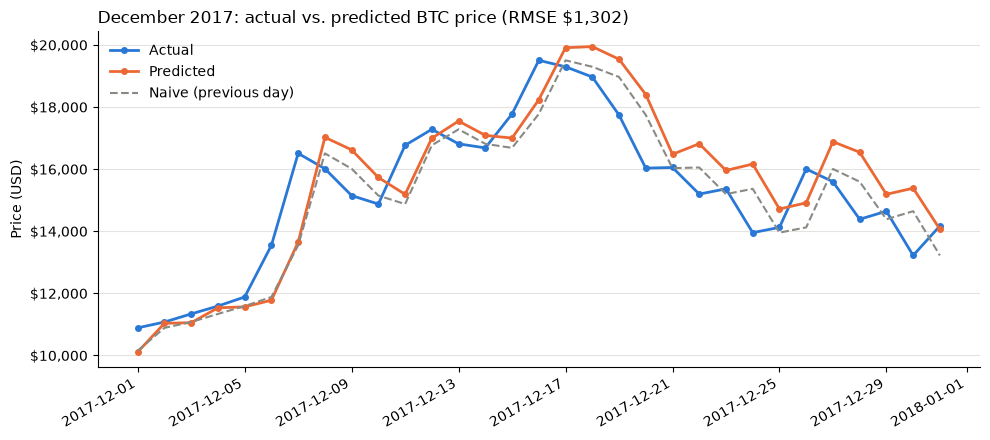

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(test['date'], y, color='#2a78d6', linewidth=2, marker='o', markersize=4, label='Actual')
ax.plot(test['date'], y_, color='#eb6834', linewidth=2, marker='o', markersize=4, label='Predicted')
ax.plot(test['date'], test['price_lag1'], color='#8a8a85', linewidth=1.5, linestyle='--', label='Naive (previous day)')
ax.set_title(f'December 2017: actual vs. predicted BTC price (RMSE ${test_rmse:,.0f})', loc='left')
ax.set_ylabel('Price (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax.grid(axis='y', color='#e4e3df', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper left')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [24]:
errors = pd.DataFrame({'date': test['date'].dt.date, 'actual': y, 'predicted': y_,
                       'error': y_ - y, 'naive_error': test['price_lag1'].values - y})
errors.reindex(errors['error'].abs().sort_values(ascending=False).index).head(5).round(2)

,date,actual,predicted,error,naive_error
6,2017-12-07,16501.97,13644.25,-2857.72,-2960.99
19,2017-12-20,16026.27,18397.11,2370.84,1710.84
23,2017-12-24,13949.18,16157.94,2208.76,1411.09
29,2017-12-30,13215.57,15380.91,2165.34,1424.57
27,2017-12-28,14380.58,16538.05,2157.47,1208.74


**Result: December 2017 test RMSE = $1,302.16**, against $1,095.08 for the naive forecast.

+ December 2017 was the most volatile month in the data: the price moved from ~$10,900 to a peak near $19,500 and back to ~$14,000, with daily moves of up to ~$3,000. Errors are therefore roughly 5x larger than on validation (~$269).
+ The model follows the previous day's price closely and adds a predicted change. In the first half of the month it tracks the rally well; after the peak on Dec 17 it keeps adding positive changes (learned from the 2016-17 uptrend that dominates training), so it overshoots on the way down (Dec 20-30 in the table above).
+ The largest single miss (Dec 7, ~-$2,860) is a jump no lag-based model could anticipate; the naive forecast misses it by the same amount.
+ The model beat the naive forecast on validation but not on test. The configuration was fixed before December was evaluated and is not changed after seeing the test result, because re-tuning on December would leak test information into model selection.

## 7. Explaining the Model with SHAP

## 8. Save Predictions